In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from PIL import Image

In [25]:
factors_list = ["efference", "forward_model", "block_sensor", "privileged_critic", "servo"]
factors = pd.read_csv("data.csv")
factors["block_sensor"] = np.logical_not(factors.blind)
subset = factors[["wandb_id"] + factors_list + ["reward_480M"]]
subset = subset.groupby(factors_list).reward_480M.agg(["mean", "std"]).sort_values("mean").reset_index()

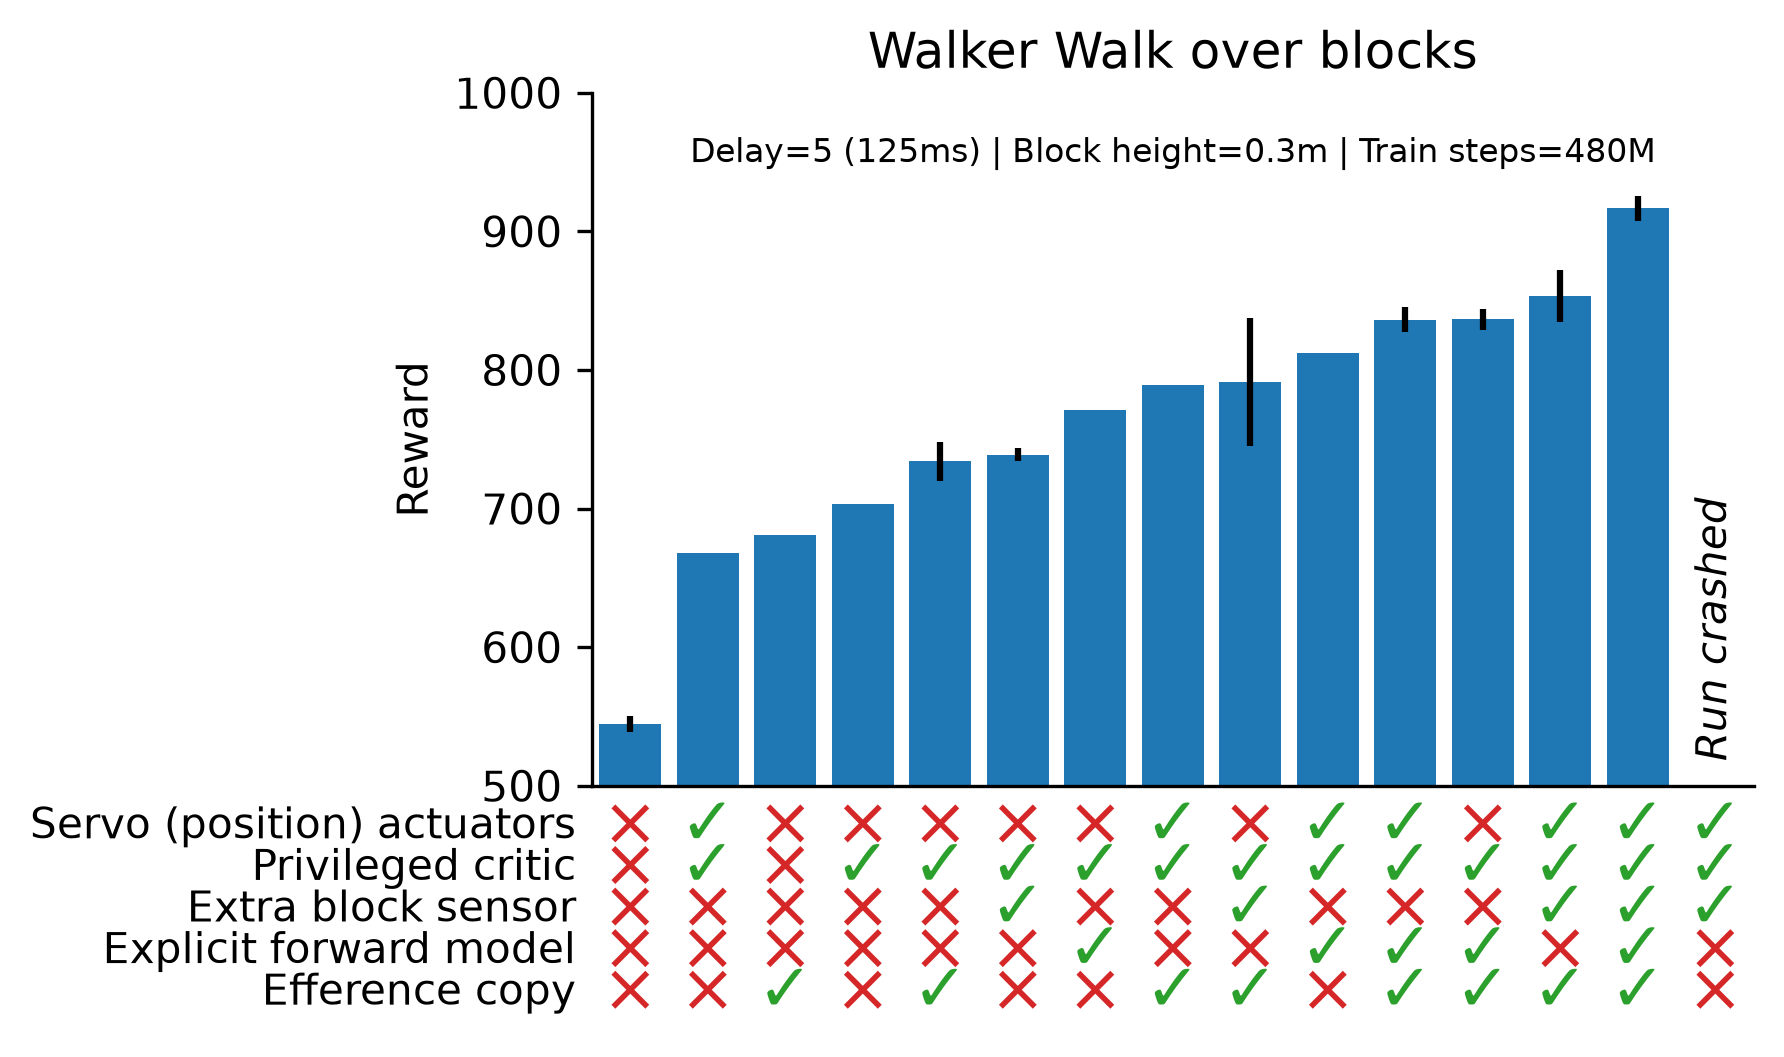

In [20]:
plt.figure(figsize=(5, 3), dpi=300)
plt.bar(subset.index, subset["mean"])
plt.errorbar(subset.index, subset["mean"], subset["std"], fmt="none", color="k")
grid_h = 30
grid_offs = 5
for i in subset.index:
    for j, f in enumerate(factors_list):
        if subset[f].iloc[i]:
            plt.text(i, (j-grid_offs)*grid_h + 500, "$\\checkmark$", color="C2", ha="center", va="center", fontsize=16)
        else:
            plt.text(i,(j-grid_offs)*grid_h + 500, "$\\times$", color="C3", ha="center", va="center", fontsize=16)
    if not np.isfinite(subset["mean"].iloc[i]):
        plt.text(i, 525, "Run crashed", rotation=90, ha="center", style="italic")
for j, f in enumerate(["Efference copy", "Explicit forward model", "Extra block sensor",
                       "Privileged critic", "Servo (position) actuators"]):
    plt.text(-0.7, (j-grid_offs)*grid_h + 500, f, color="k", ha="right", va="center")#, fontsize=11)
plt.xticks([])
plt.ylim(500, 1000)
plt.ylabel("Reward")
plt.xlim(-0.5, 14.5)
plt.title("Walker Walk over blocks")
plt.text(7, 950, "Delay=5 (125ms) | Block height=0.3m | Train steps=480M", ha="center",fontsize=8)
sns.despine()
#plt.ylim(0, 7)

In [98]:
long_labels = {
    "efference": "Efference copy",
    "forward_model": "Explicit forward model",
    "block_sensor": "Extra block sensor",
    "privileged_critic": "Privileged critic",
    "servo": "Servo (position) actuators",
}
conditions = {
    "efference": ["Efference copy", "No efference copy"],
    "forward_model": ["Forward model + MLP", "MLP only"],
    "block_sensor": ["Extra block sensor", "Proprioception only"],
    "privileged_critic": ["Undelayed critic", "Delayed critic"],
    "servo": [ "Position actions", "Torque actions"],
}

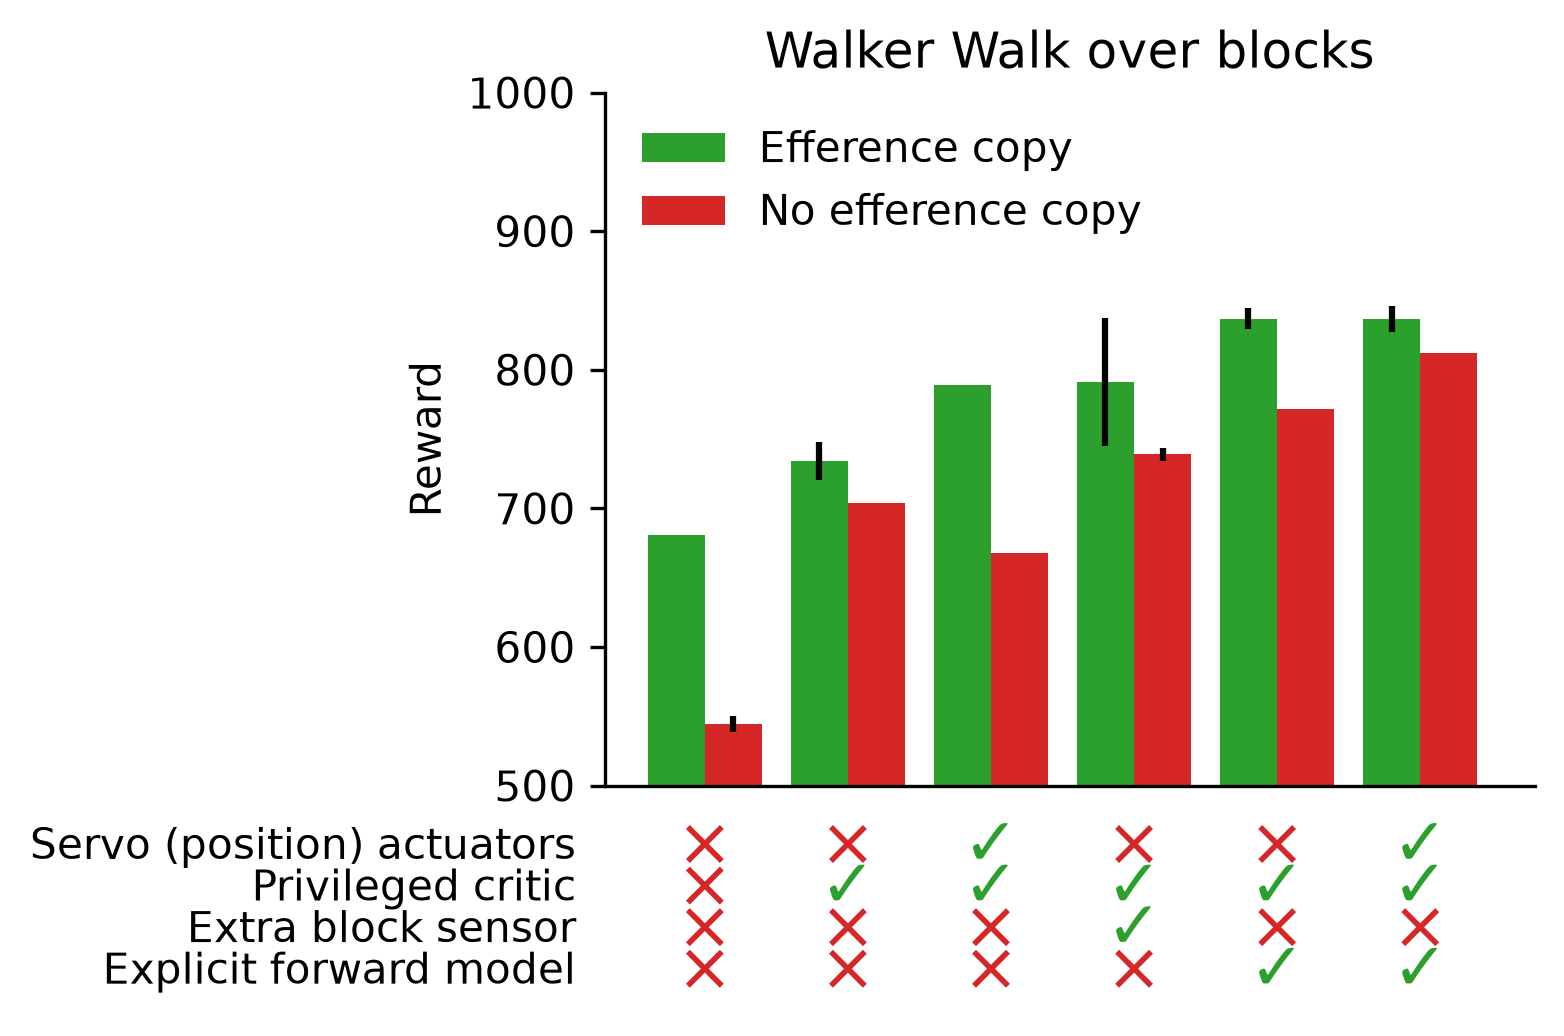

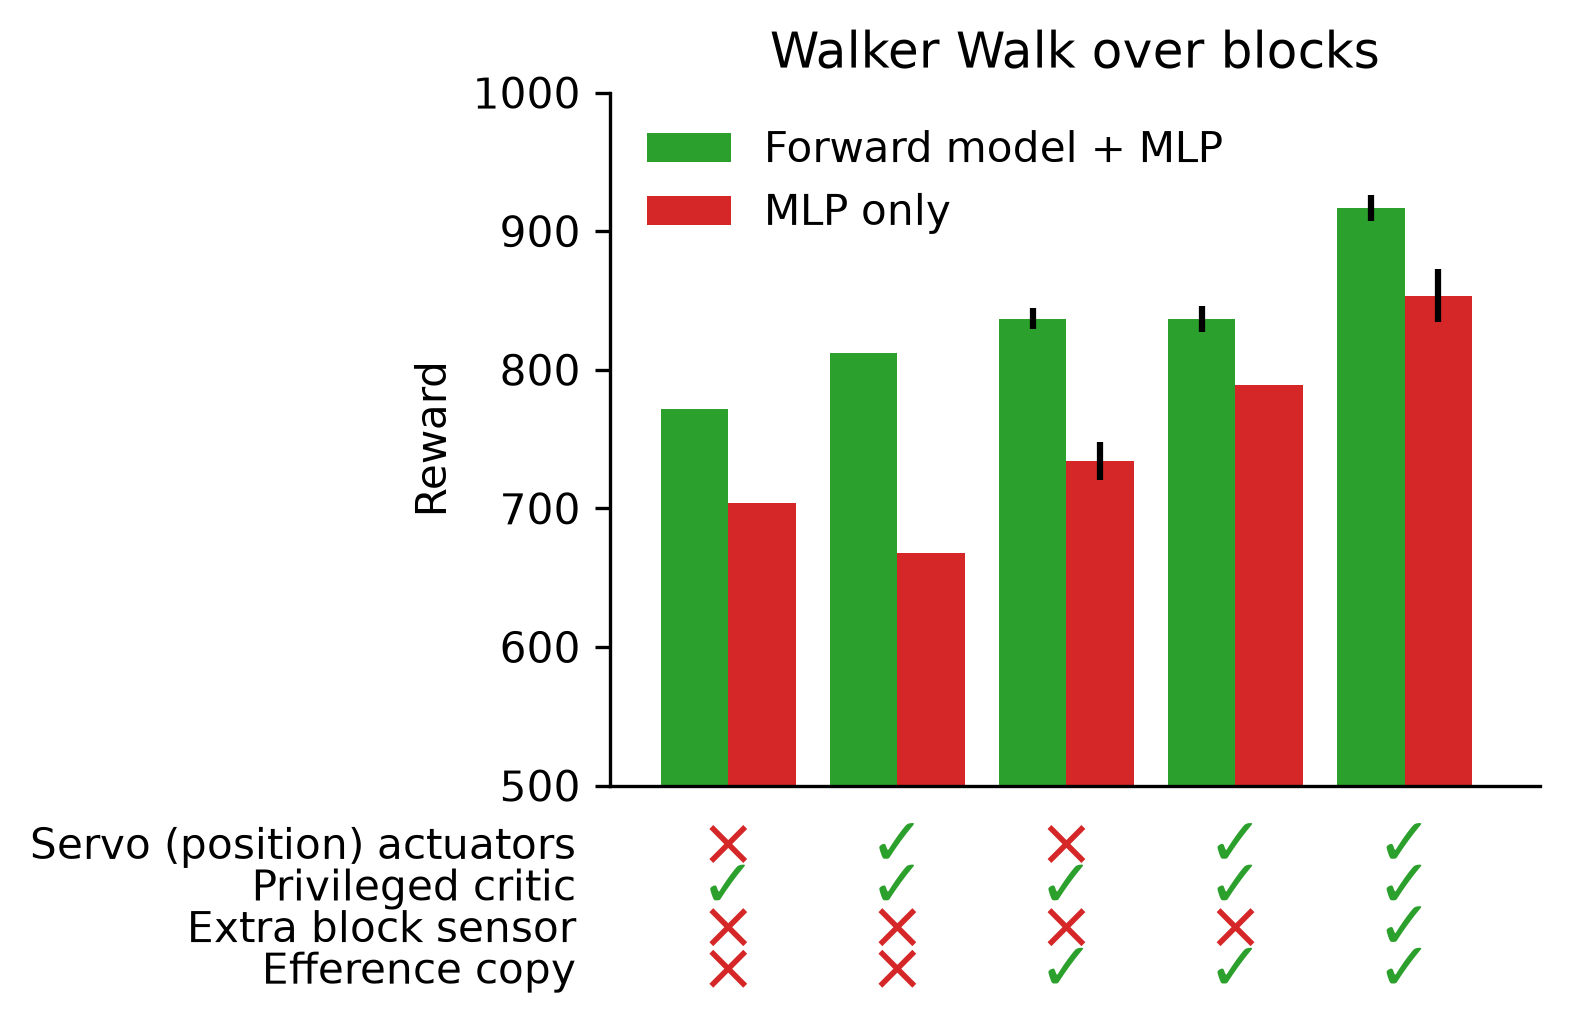

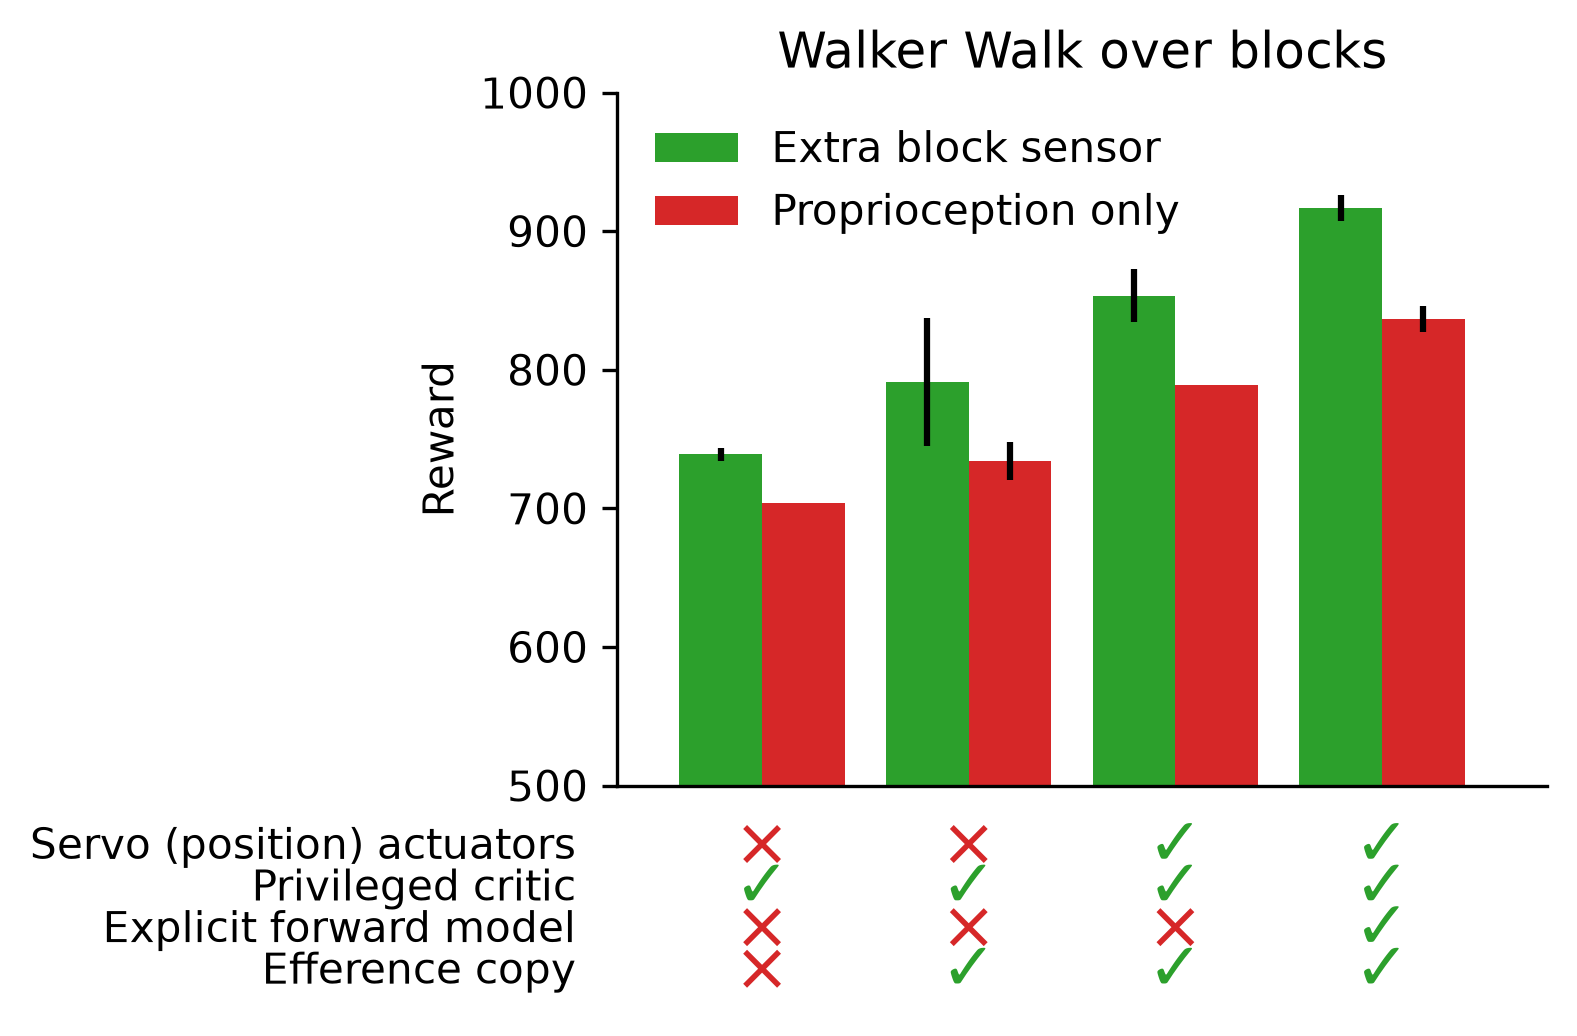

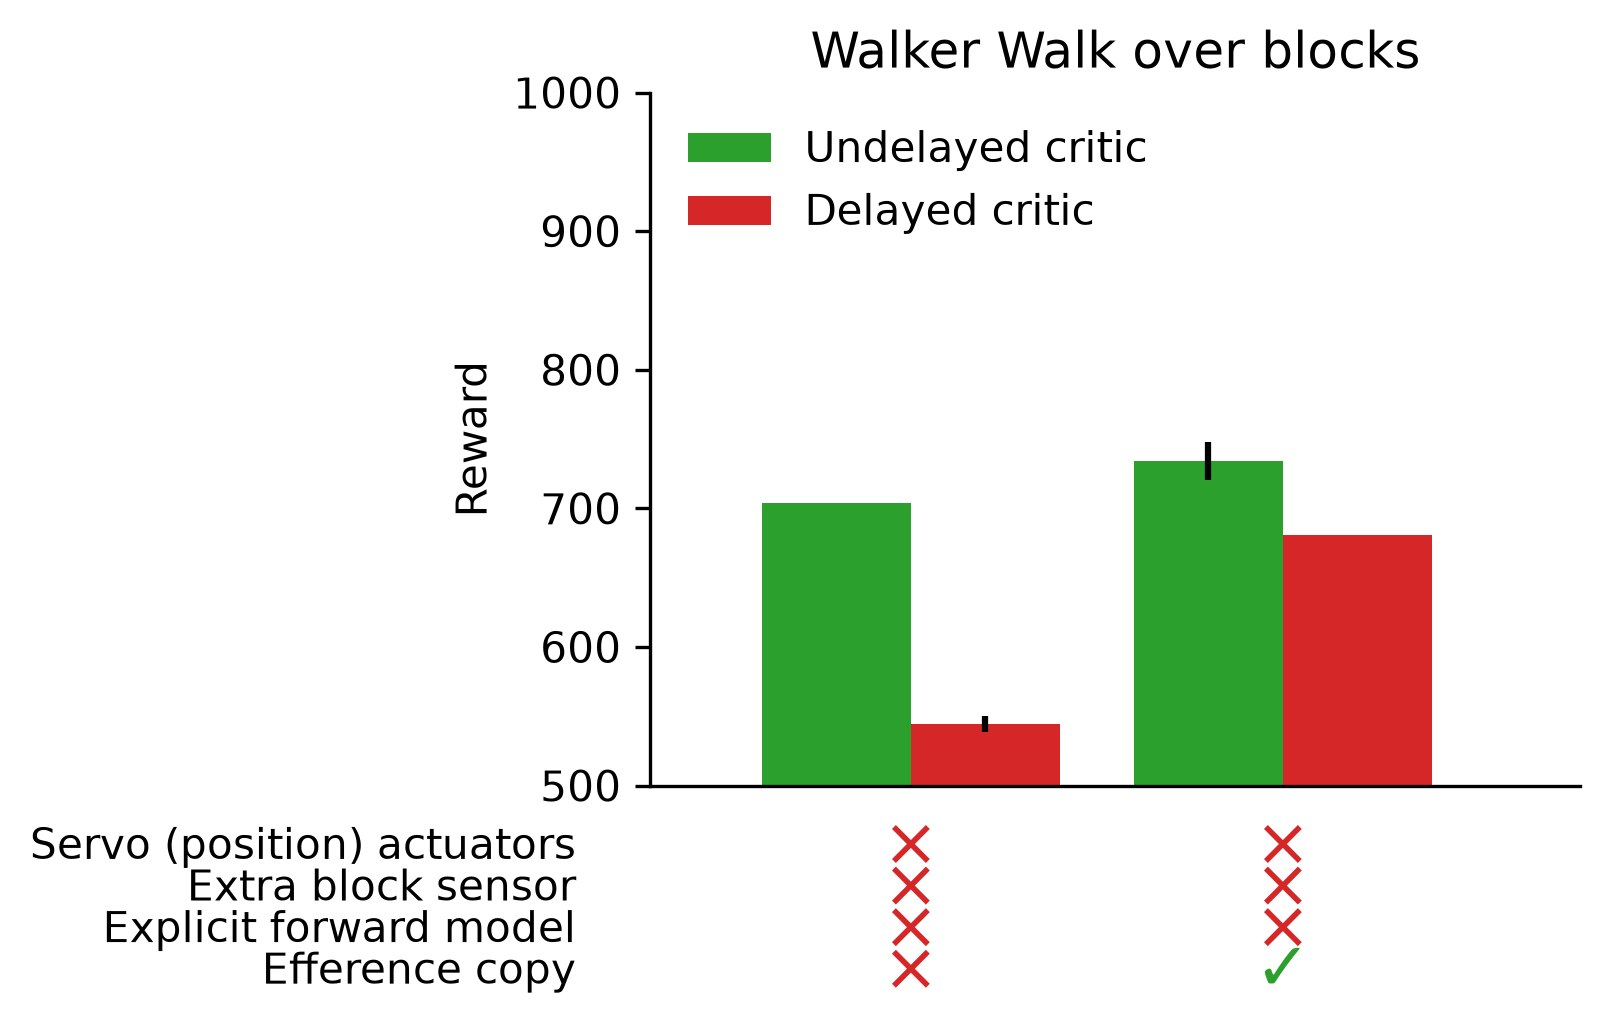

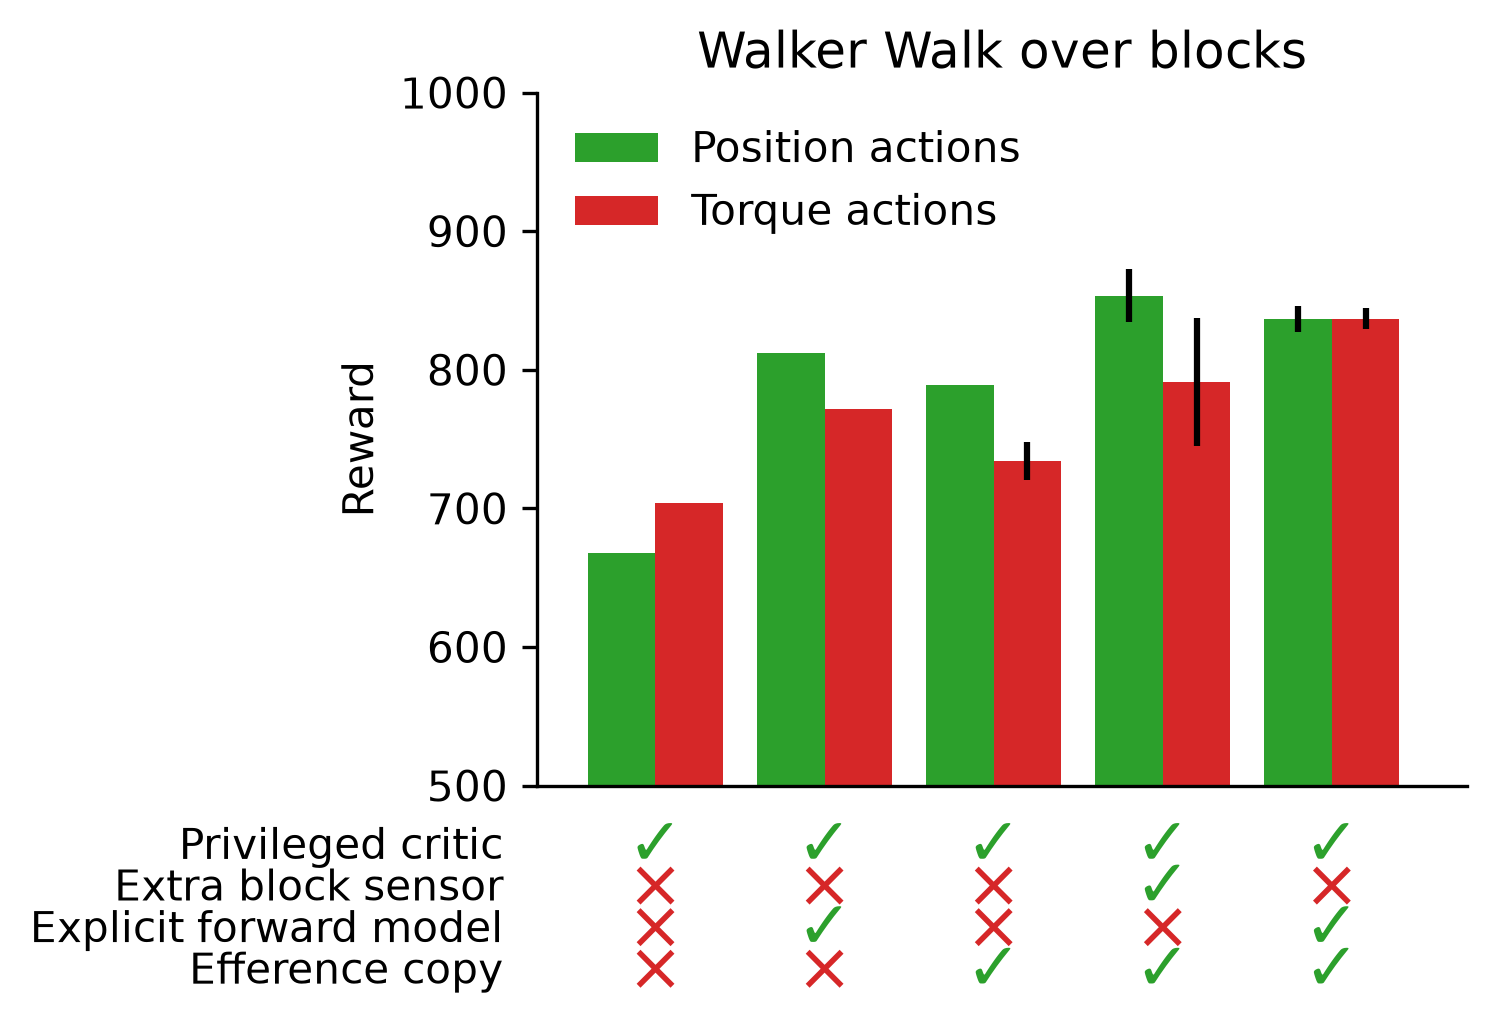

In [100]:
for i in range(5):
    sorted_factors = factors_list[:i] + factors_list[i+1:] + factors_list[i:i+1]
    df = subset.set_index(sorted_factors)
    df = df.unstack().dropna(subset=[("mean",True), ("mean", False)]).reset_index()

    plt.figure(figsize=(4, 3), dpi=300)
    plt.bar(df.index, df["mean", True], 0.4, color="C2", label=conditions[sorted_factors[-1]][0])
    plt.bar(df.index+0.4, df["mean", False], 0.4, color="C3", label=conditions[sorted_factors[-1]][1])
    plt.errorbar(df.index, df["mean", True], df["std", True], fmt="none", color="k")
    plt.errorbar(df.index+0.4, df["mean", False], df["std", False], fmt="none", color="k")
    grid_h = 30
    grid_offs = 4.5
    for i in df.index:
        for j, f in enumerate(sorted_factors[:4]):
            if df[f].iloc[i]:
                plt.text(i+0.2, (j-grid_offs)*grid_h + 500, "$\\checkmark$", color="C2", ha="center", va="center", fontsize=16)
            else:
                plt.text(i+0.2,(j-grid_offs)*grid_h + 500, "$\\times$", color="C3", ha="center", va="center", fontsize=16)
    for j, f in enumerate(sorted_factors[:4]):
        plt.text(-0.7, (j-grid_offs)*grid_h + 500, long_labels[f], color="k", ha="right", va="center")#, fontsize=11)
    plt.xticks([])
    plt.ylim(500, 1000)
    plt.ylabel("Reward")
    plt.xlim(-0.5, len(df))
    plt.title("Walker Walk over blocks")
    plt.legend(loc="upper left", frameon=False)
    #plt.text(len(df)/2, 950, "Delay=5 (125ms) | Block height=0.3m | Train steps=480M", ha="center",fontsize=8)
    sns.despine()
    plt.show()